# Linear Algebra for Computational Neuroscience — Practical Exercises

Wealready covered **vectors & vector spaces**, **matrices**, and **eigenstuff**
(eigenvalues/eigenvectors). This notebook puts those tools to work on two exercises
that show up constantly in computational neuroscience:

1. **Build PCA from scratch** and use it to find low-dimensional structure in
   simulated neural population activity (a "neural manifold").
2. **Show that matrices are linear transformations** by implementing image
   kernels/filters (like the receptive fields of visual neurons) both as
   sliding-window convolutions *and* as explicit matrix multiplications, then
   tie the eigenstuff back in.

Each exercise is self-contained, with the math written out alongside the code.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(42)
plt.rcParams['figure.facecolor'] = 'white'
from scipy.linalg import null_space


---
## Exercise 1 — PCA from scratch on simulated neural population activity

**The neuroscience motivation.** Suppose you record from $N$ neurons simultaneously
while an animal performs a task. At every point in time you get a vector in
$\mathbb{R}^N$ — one firing rate per neuron. Even though the *recording* lives in a
high-dimensional space (one axis per neuron), the actual *dynamics* driving the
population are often much lower-dimensional: a handful of latent variables
(e.g. "phase in a rhythmic movement", "evidence accumulated so far", "stimulus
orientation") that get mixed together and read out by many neurons at once.
This is the idea of a **neural manifold**.

PCA is the simplest tool for finding that low-dimensional structure: it looks
for the directions in neuron-space along which the population activity varies
the most, and it does this by finding the eigenvectors of the covariance matrix.

### 1.1 Simulate a neural population recording

We'll simulate 40 neurons whose firing rates are secretly driven by a 2D
rotational latent trajectory (think: a rhythmic behavior, like a limb cycling
through a gait, or a slow oscillation in cortical state), each neuron reading
out some random mixture of the two latent axes, plus independent noise.


In [ ]:
n_neurons = 40
n_time = 500
t = np.linspace(0, 8 * np.pi, n_time)

# 2D latent trajectory: a rotation (e.g. phase of a rhythmic process)
latent = np.stack([np.sin(t), np.cos(t)], axis=1)          # (n_time, 2)

# each neuron reads out a random mixture of the two latent axes
mixing = rng.normal(size=(2, n_neurons))                    # (2, n_neurons)

firing = latent @ mixing                                    # (n_time, n_neurons)
noise = rng.normal(scale=0.5, size=firing.shape)
X = firing + noise                                           # our "recording": rows=time, cols=neurons

print(f"Data matrix X: {X.shape[0]} time samples x {X.shape[1]} neurons")


Data matrix X: 500 time samples x 40 neurons


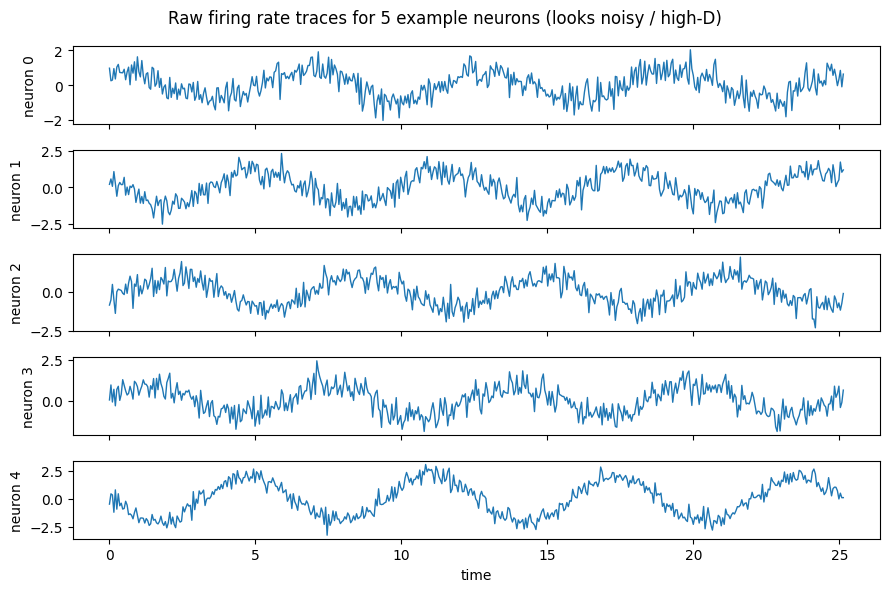

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(9, 6), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t, X[:, i], lw=1)
    ax.set_ylabel(f'neuron {i}')
axes[-1].set_xlabel('time')
fig.suptitle('Raw firing rate traces for 5 example neurons (looks noisy / high-D)')
plt.tight_layout()
plt.show()


Each individual neuron's trace looks like a somewhat noisy oscillation, and
with 40 of them it's not obvious there's a shared 2D structure underneath.
That's exactly the problem PCA is built to solve.

### 1.2 PCA, step by step

Given a centered data matrix $X \in \mathbb{R}^{T \times N}$ (T time samples,
N neurons), PCA finds an orthonormal basis of neuron-space,
$v_1, v_2, \dots, v_N$, ranked so that projecting the data onto $v_1$ captures
the most variance, $v_2$ the next most (subject to being orthogonal to $v_1$),
and so on.

**Step 1 — center the data.** Subtract each neuron's mean firing rate so we're
looking at fluctuations around the mean, not the mean itself.

$$\tilde{X} = X - \bar{X}$$


In [ ]:
# TODO: Center the matrix X we built above:
X_centered = X - X.mean(axis=0)

**Step 2 — build the covariance matrix.** The $(i, j)$ entry of the covariance
matrix tells us how neuron $i$'s fluctuations co-vary with neuron $j$'s:

$$C = \frac{1}{T - 1} \tilde{X}^\top \tilde{X} \quad \in \mathbb{R}^{N \times N}$$

$C$ is symmetric positive semi-definite by construction.


In [ ]:
# TODO: Compute the covariance matrix.
T = X_centered.shape[0] #nb of time samples
C = (X_centered.T @ X_centered)/(T-1) #the covar matrix
print("Covariance matrix shape:", C.shape)
print("Symmetric?", np.allclose(C, C.T))

Covariance matrix shape: (40, 40)
Symmetric? True


**Step 3 — eigendecompose the covariance matrix.** This is where the
eigenstuff comes in directly:

$$C v_k = \lambda_k v_k$$

- The eigenvectors $v_k$ are the **principal axes** — directions in
  neuron-space along which population activity co-varies as a rigid pattern.
- The eigenvalues $\lambda_k$ tell you **how much variance** is captured
  along each axis.

Because $C$ is symmetric, we can use `np.linalg.eigh`, which is faster and
numerically more stable than the general `eig` and guarantees real,
orthonormal eigenvectors.

After obtaining the eigenvalues, we can compute a metric called **Explained Variance Ratio (EVR)**, which allows us to determine how much variance is described by the axis associated to the eigenvalue. It is simply the eigenvalue associated to the eigenvector divided by the sum of all eigenvalues.


In [ ]:
eigvals, eigvecs = np.linalg.eigh(C)          # ascending order by default

# TODO: sort descending, biggest variance direction first, then compute EVR
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:,order]                 # each COLUMN is an eigenvector

explained_var_ratio = eigvals/eigvals.sum()

print("Explained variance ratio, first 6 components:")
print(explained_var_ratio[:6])


Explained variance ratio, first 6 components:
[0.445 0.274 0.012 0.011 0.011 0.01 ]


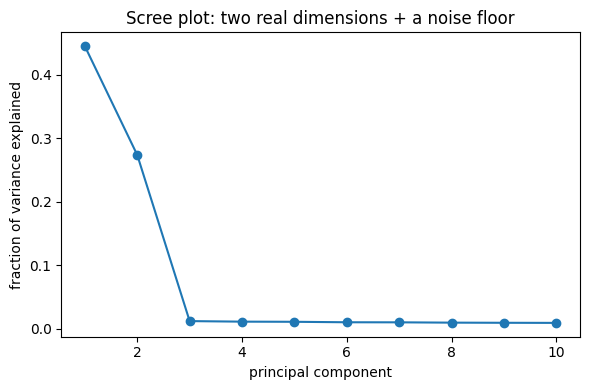

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, 11), explained_var_ratio[:10], 'o-')
ax.set_xlabel('principal component')
ax.set_ylabel('fraction of variance explained')
ax.set_title('Scree plot: two real dimensions + a noise floor')
plt.tight_layout()
plt.show()


The scree plot should show two components sticking up well above a roughly
flat noise floor — exactly matching the fact that we built the data from a 2D
latent trajectory plus isotropic noise. This "elbow" is the standard way
people decide how many dimensions a neural population's activity effectively
lives in.

### 1.3 Project onto the top components (dimensionality reduction)

Projecting the centered data onto the top $k$ eigenvectors gives the
**latent trajectory**, i.e. each neuron's activity is a mixture, so we're
undoing the mixing:

$$Z = \tilde{X} V_k, \qquad V_k = [v_1, \dots, v_k]$$


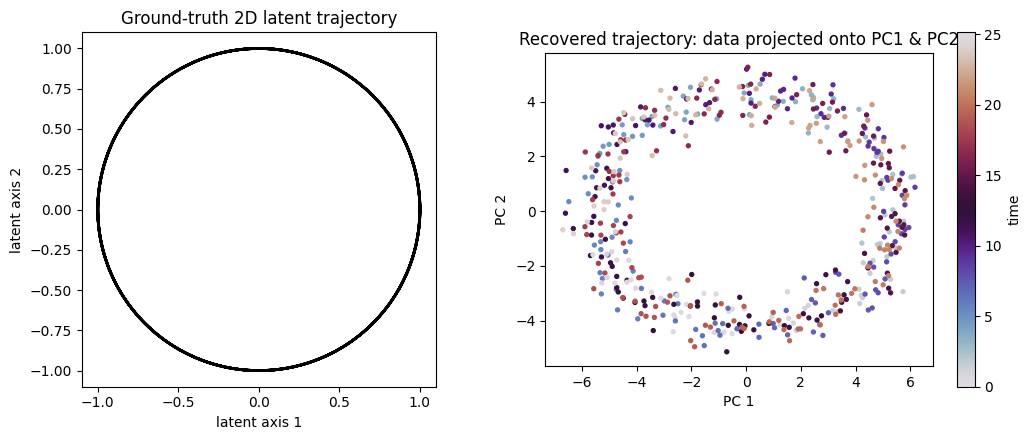

In [ ]:
k = 2
V_k = eigvecs[:, :k]
Z = X_centered @ V_k                     # (n_time, k) -- the recovered latent trajectory

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(latent[:, 0], latent[:, 1], lw=2, color='k')
axes[0].set_title('Ground-truth 2D latent trajectory')
axes[0].set_xlabel('latent axis 1'); axes[0].set_ylabel('latent axis 2')
axes[0].set_aspect('equal')

sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=t, cmap='twilight', s=8)
axes[1].set_title('Recovered trajectory: data projected onto PC1 & PC2')
axes[1].set_xlabel('PC 1'); axes[1].set_ylabel('PC 2')
axes[1].set_aspect('equal')
plt.colorbar(sc, ax=axes[1], label='time')
plt.tight_layout()
plt.show()


PCA recovers a rotated/rescaled version of the true 2D loop purely by looking
at covariance across 40 noisy neurons — it has no idea the loop existed, it
just found the two directions in neuron-space with the most shared variance.
(PCA is only guaranteed up to rotation/reflection/scaling, so the recovered
loop won't exactly match the ground truth axis-for-axis, but the *shape* —
a loop — is preserved.)

### 1.4 Reconstruction error vs. number of components

We can reconstruct an approximation of the original data using only $k$
components:

$$\hat{X} = Z V_k^\top + \bar{X} = \tilde{X} V_k V_k^\top + \bar{X}$$

and see how reconstruction error drops as $k$ grows — this is the same
"how many dimensions do I actually need" question as the scree plot, from a
different angle.


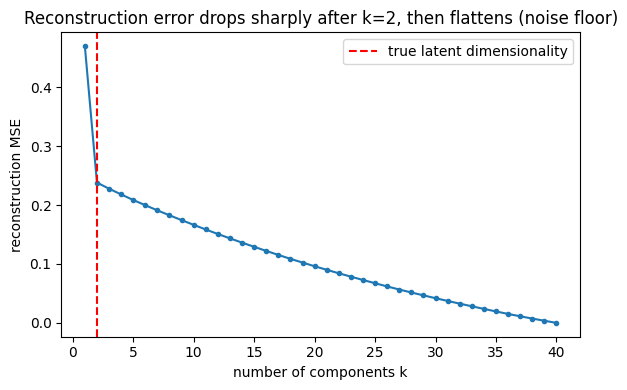

In [ ]:
def reconstruct(X_centered, eigvecs, k, mean):
    V_k = eigvecs[:, :k]
    Z = X_centered @ V_k
    return Z @ V_k.T + mean

mean = X.mean(axis=0, keepdims=True)
mse_by_k = []
for k_ in range(1, n_neurons + 1):
    X_hat = reconstruct(X_centered, eigvecs, k_, mean)
    mse_by_k.append(np.mean((X - X_hat) ** 2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, n_neurons + 1), mse_by_k, 'o-', ms=3)
ax.axvline(2, color='r', ls='--', label='true latent dimensionality')
ax.set_xlabel('number of components k')
ax.set_ylabel('reconstruction MSE')
ax.legend()
ax.set_title('Reconstruction error drops sharply after k=2, then flattens (noise floor)')
plt.tight_layout()
plt.show()


### 1.5 Sanity check against `sklearn.decomposition.PCA`

Our from-scratch version should match scikit-learn's PCA (up to the sign of
each eigenvector, which is arbitrary — $v$ and $-v$ span the same axis).


In [ ]:
from sklearn.decomposition import PCA

skpca = PCA(n_components=6)
skpca.fit(X)

print("From scratch:  ", explained_var_ratio[:6])
print("sklearn PCA:   ", skpca.explained_variance_ratio_)
print("Match?", np.allclose(explained_var_ratio[:6], skpca.explained_variance_ratio_, atol=1e-8))


From scratch:   [0.445 0.274 0.012 0.011 0.011 0.01 ]
sklearn PCA:    [0.445 0.274 0.012 0.011 0.011 0.01 ]
Match? True


**Takeaways**
- PCA *is* an eigendecomposition of the covariance matrix — nothing more exotic than that.
- Eigenvectors of $C$ = principal axes in neuron-space; eigenvalues = variance along each axis.
- This is exactly how neuroscientists talk about "the dimensionality of neural population activity" and visualize "neural trajectories" on a low-D manifold.

**Optional: try it yourself!** Change `mixing` to have 3 latent axes instead of 2, or make the
noise correlated across neurons (e.g. `noise = rng.normal(...) @ some_matrix`) and see
how the scree plot and reconstruction curve change.


In [ ]:
# TODO - this is homework, we can discuss it over Discord or in another tutorial ^^

---
## Exercise 2 — Matrices as linear transforms: image kernels as "receptive fields"

**The neuroscience motivation.** Neurons in early visual cortex (V1) respond
to small patches of the visual field — their **receptive field**. Many simple
cells behave almost exactly like a small convolution kernel: they compute a
weighted sum of nearby pixels (edge detectors, oriented Gabor filters, etc.),
which is exactly what an image filter/kernel does. Convolutional neural
networks borrowed this idea directly from visual neuroscience.

The point of this exercise: **convolving an image with a kernel is a linear
transformation**, and any linear transformation can be written as a single
matrix multiplication. We'll build the same operation two ways — as a
sliding-window convolution, and as an explicit matrix — and show they give
identical results.

### 2.1 Build a small synthetic image

(We generate this ourselves instead of downloading a file, so the notebook
runs anywhere without needing network / image files.)


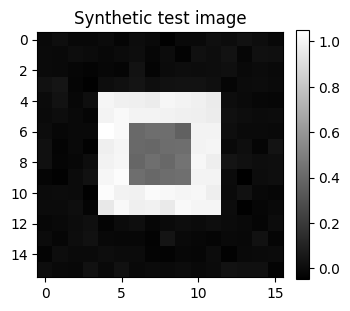

In [ ]:
size = 16
img = np.zeros((size, size))
img[4:12, 4:12] = 1.0       # a bright square
img[6:10, 6:10] = 0.4       # a darker square inside it (creates internal edges)
img += rng.normal(scale=0.02, size=img.shape)   # tiny bit of sensor noise

plt.figure(figsize=(3.5, 3.5))
plt.imshow(img, cmap='gray')
plt.title('Synthetic test image')
plt.colorbar(fraction=0.046)
plt.show()


### 2.2 Convolution the "obvious" way: sliding the kernel over the image

For a kernel $K$ of size $(2p+1) \times (2p+1)$, the filtered image is

$$Y[i, j] = \sum_{a=-p}^{p} \sum_{b=-p}^{p} K[a, b] \; X[i+a,\, j+b]$$

i.e. slide the kernel over every pixel, multiply element-wise with the patch
underneath, and sum. We zero-pad the border so the output is the same size
as the input.


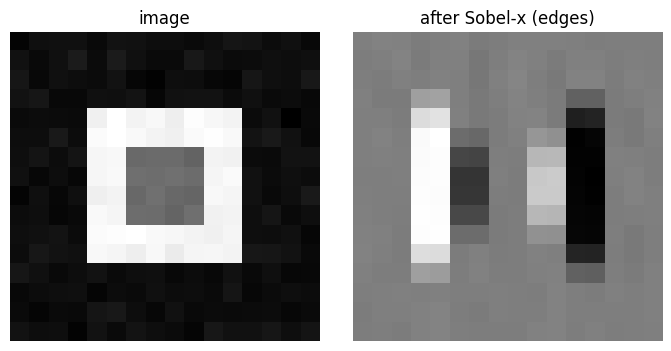

In [ ]:
def conv2d_manual(image, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    padded = np.pad(image, ((ph, ph), (pw, pw)), mode='constant')
    out = np.zeros_like(image)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            patch = padded[i:i + kh, j:j + kw]
            out[i, j] = np.sum(patch * kernel)
    return out

sobel_x = np.array([[-1, 0, 1],
                     [-2, 0, 2],
                     [-1, 0, 1]], dtype=float)   # vertical-edge detector

edges = conv2d_manual(img, sobel_x)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(img, cmap='gray'); axes[0].set_title('image')
axes[1].imshow(edges, cmap='gray'); axes[1].set_title('after Sobel-x (edges)')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()


### 2.3 The *same* operation as a matrix multiplication

Here's the key idea: flatten the image into a single long vector
$x \in \mathbb{R}^{HW}$ (stack the rows). Convolution with a fixed kernel is
**linear** in the pixel values — doubling every pixel doubles every output,
and convolving a sum of two images equals the sum of convolving each one
separately. Any linear map from $\mathbb{R}^{HW} \to \mathbb{R}^{HW}$ can be
written as multiplication by some matrix $M \in \mathbb{R}^{HW \times HW}$:

$$y = Mx$$

We build $M$ by working out, for every output pixel, which input pixels
(and with what kernel weight) contribute to it — each row of $M$ is just the
kernel "stamped" at the right shifted location (a sparse, banded structure
called a *block-Toeplitz* matrix).


In [ ]:
def build_conv_matrix(image_shape, kernel):
    h, w = image_shape
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    N = h * w
    M = np.zeros((N, N))
    for i in range(h):
        for j in range(w):
            out_idx = i * w + j
            for ki in range(kh):
                for kj in range(kw):
                    ii, jj = i + ki - ph, j + kj - pw
                    if 0 <= ii < h and 0 <= jj < w:
                        in_idx = ii * w + jj
                        M[out_idx, in_idx] = kernel[ki, kj]
    return M

M_sobel = build_conv_matrix(img.shape, sobel_x)
print("Convolution matrix M shape:", M_sobel.shape, " (huge, but very sparse)")
print("Fraction of nonzero entries:", np.mean(M_sobel != 0))

edges_via_matrix = (M_sobel @ img.flatten()).reshape(img.shape)

print("Identical to manual convolution?",
      np.allclose(edges, edges_via_matrix, atol=1e-10))


Convolution matrix M shape: (256, 256)  (huge, but very sparse)
Fraction of nonzero entries: 0.02105712890625
Identical to manual convolution? True


Same numbers, two completely different-looking implementations — because a
convolution *is* a linear transform, and a matrix is nothing more than "the
thing you multiply a vector by to apply a linear transform." This is the same
statement as "matrices represent linear maps" from the matrices unit, just
applied to a filter/kernel instead of e.g. a rotation or projection.

### 2.4 A gallery of kernels (receptive-field types)

Different kernels correspond to different "cell types". A Gabor filter in
particular is a standard model of a V1 simple-cell receptive field — it's
tuned to a spatial frequency and orientation, just like real V1 neurons.


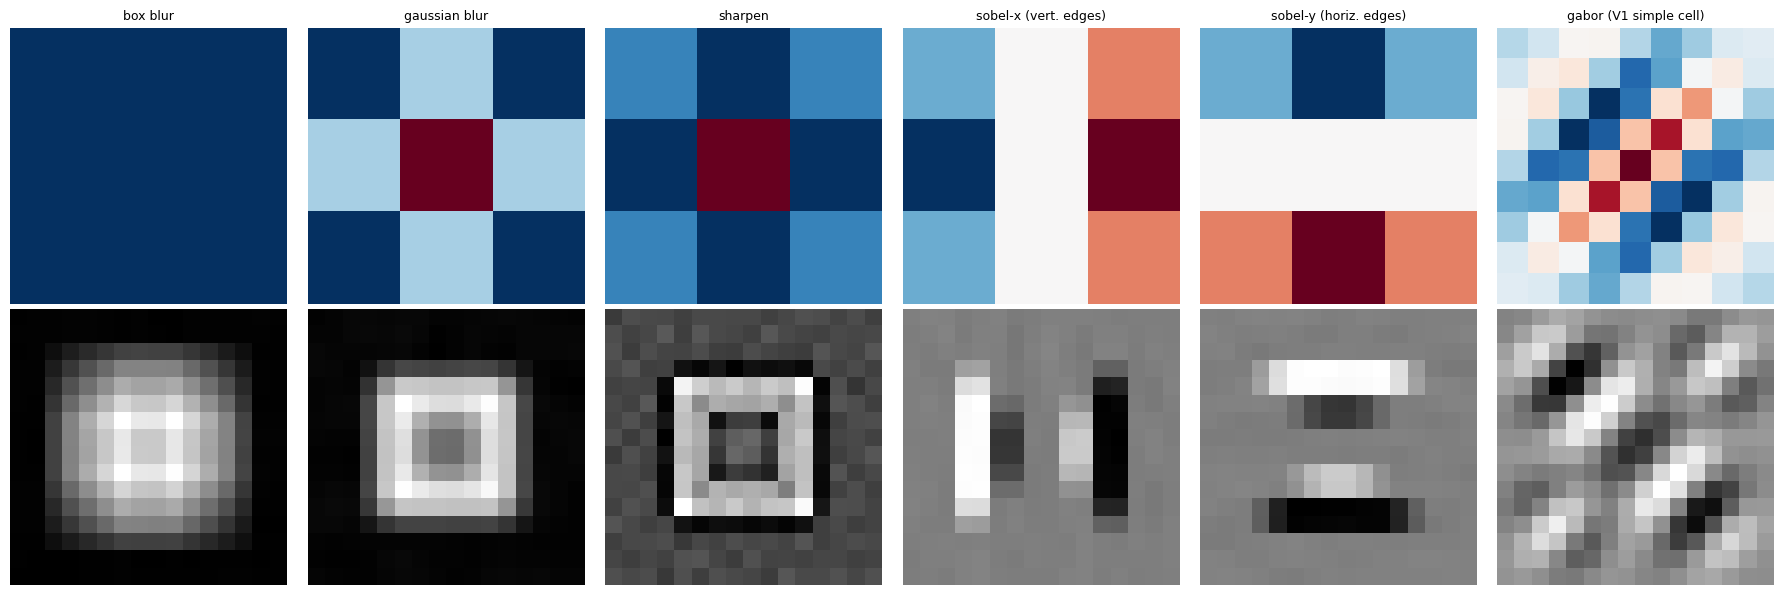

In [ ]:
def gabor_kernel(size=9, sigma=2.5, theta=0.0, freq=0.25, phase=0.0):
    ax = np.arange(size) - size // 2
    xx, yy = np.meshgrid(ax, ax)
    x_theta = xx * np.cos(theta) + yy * np.sin(theta)
    y_theta = -xx * np.sin(theta) + yy * np.cos(theta)
    gaussian = np.exp(-(x_theta**2 + y_theta**2) / (2 * sigma**2))
    sinusoid = np.cos(2 * np.pi * freq * x_theta + phase)
    return gaussian * sinusoid

box_blur = np.ones((5, 5)) / 25
gauss_blur = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float); gauss_blur /= gauss_blur.sum()
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
sobel_y = sobel_x.T
gabor = gabor_kernel(theta=np.pi / 4)

kernels = {
    'box blur': box_blur,
    'gaussian blur': gauss_blur,
    'sharpen': sharpen,
    'sobel-x (vert. edges)': sobel_x,
    'sobel-y (horiz. edges)': sobel_y,
    'gabor (V1 simple cell)': gabor,
}

fig, axes = plt.subplots(2, len(kernels), figsize=(3 * len(kernels), 6))
for col, (name, kern) in enumerate(kernels.items()):
    axes[0, col].imshow(kern, cmap='RdBu_r')
    axes[0, col].set_title(name, fontsize=9)
    axes[0, col].axis('off')

    filtered = conv2d_manual(img, kern)
    axes[1, col].imshow(filtered, cmap='gray')
    axes[1, col].axis('off')

axes[0, 0].set_ylabel('kernel', fontsize=10)
axes[1, 0].set_ylabel('filtered image', fontsize=10)
plt.tight_layout()
plt.show()


### 2.5 Tying eigenstuff back in: what repeated filtering converges to

Here's a nice connection back to the eigenstuff unit. The Gaussian blur
kernel is symmetric, so its convolution matrix $M$ is symmetric too, and it
has real eigenvalues/eigenvectors. Also notice the kernel's weights sum to 1
— that means a perfectly uniform (constant-value) image is a **fixed point**
of blurring: blur a flat gray image and you get the same flat gray image
back. In eigenstuff language, the constant image is (approximately) the
**eigenvector with eigenvalue closest to 1** — the dominant eigenvector.

That means if we apply the blur matrix over and over to *any* starting image
(power iteration!), it should converge toward that flat, dominant eigenvector,
at a rate set by how close the second-largest eigenvalue is to the first.


Largest eigenvalue of the blur matrix: 0.9712
Second largest: 0.9290  (gap sets the convergence speed)


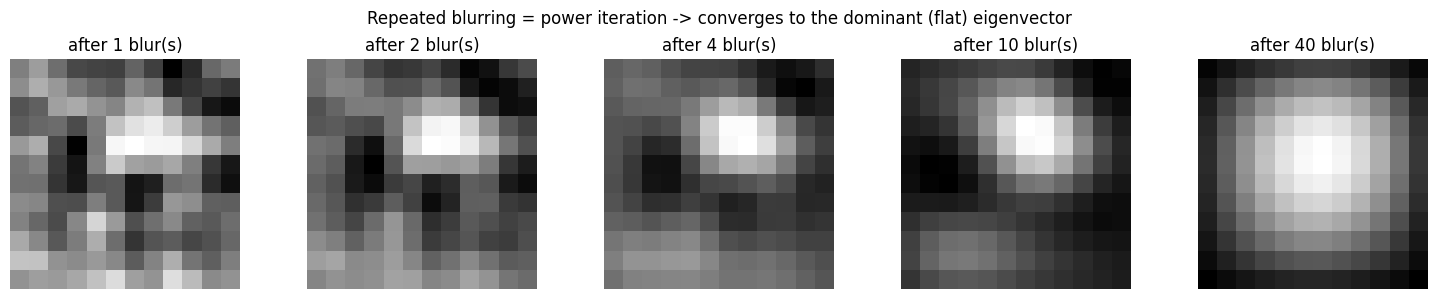

Cosine similarity between the converged image and the true top eigenvector: 0.9930


In [ ]:
small_shape = (12, 12)
M_blur = build_conv_matrix(small_shape, gauss_blur)

eigvals_b, eigvecs_b = np.linalg.eigh(M_blur)
top = np.argmax(eigvals_b)
print(f"Largest eigenvalue of the blur matrix: {eigvals_b[top]:.4f}")
print(f"Second largest: {np.sort(eigvals_b)[-2]:.4f}  (gap sets the convergence speed)")

v = rng.normal(size=small_shape).flatten()
snapshots = []
for i in range(40):
    v = M_blur @ v
    v = v / np.linalg.norm(v)
    if i in (0, 1, 3, 9, 39):
        snapshots.append((i + 1, v.reshape(small_shape).copy()))

fig, axes = plt.subplots(1, len(snapshots), figsize=(3 * len(snapshots), 3))
for ax, (i, frame) in zip(axes, snapshots):
    ax.imshow(frame, cmap='gray')
    ax.set_title(f'after {i} blur(s)')
    ax.axis('off')
plt.suptitle('Repeated blurring = power iteration -> converges to the dominant (flat) eigenvector')
plt.tight_layout()
plt.show()

top_eigvec_img = eigvecs_b[:, top].reshape(small_shape)
final_dir = v.reshape(small_shape)
cos_sim = np.abs(np.dot(v, eigvecs_b[:, top]))
print(f"Cosine similarity between the converged image and the true top eigenvector: {cos_sim:.4f}")


Starting from pure random noise, repeatedly applying the exact same linear
transform (blurring) drives the image toward a single direction in
$\mathbb{R}^{HW}$ — the dominant eigenvector of the blur matrix — regardless
of where we started. This is *power iteration*, the same algorithm you can
use to find the top eigenvector of any matrix without ever computing a full
eigendecomposition, and it's the same underlying idea whether the matrix is a
covariance matrix (Exercise 1) or a convolution kernel (Exercise 2).

**Takeaways**
- A convolution/filter is a linear transform, so it can always be written as `y = Mx`; sliding-window convolution and matrix multiplication are the same computation.
- Different kernels model different receptive-field types (edge detectors, blurs, oriented Gabor filters like V1 simple cells).
- Repeated application of a linear map (power iteration) drives any vector toward the dominant eigenvector — true for blur kernels and just as true for the covariance matrices behind PCA.

**Optional: try it yourself!** Build the convolution matrix for `sobel_x` on a small image, eigendecompose it (use `np.linalg.eig`, not `eigh`, since it's *not* symmetric), and see what its eigenvalues look like compared to the symmetric blur case.


---
## Exercise 3 — The retina→LGN circuit: invertibility & eigendecomposition

This is the exact circuit from lecture: two retinal ganglion cells with
responses $r = [r_1, r_2]$ feed into two LGN neurons with responses
$g = [g_1, g_2]$ through a fixed weight matrix $W$:

$$W r = g, \qquad W = \begin{bmatrix} 3 & 1 \\ 0 & 2 \end{bmatrix}$$

We'll use it to make three ideas from lecture concrete: solving for the
input given the output, checking invertibility via rank/null space, and
eigendecomposing $W$ to see why the "eigenbasis" is special.


In [ ]:
W = np.array([[3., 1.],
              [0., 2.]])

r = np.array([1., 2.])       # true retinal activity
g = W @ r                    # what the LGN neurons see
print("retinal activity r:", r)
print("LGN activity g = Wr:", g)


retinal activity r: [1. 2.]
LGN activity g = Wr: [5. 4.]


### 3.1 Can we recover $r$ from $g$? (Is $W$ invertible?)

If a downstream brain area only observes $g$ (LGN output), can it always
work out what the retina originally sent? Only if $W$ is **invertible** —
i.e. square, with a null space containing nothing but the zero vector
(equivalently, `rank(W)` equals the number of columns).


In [ ]:
rank_W = np.linalg.matrix_rank(W)
det_W = np.linalg.det(W)
null_W = null_space(W)

print(f"rank(W) = {rank_W}  (out of 2 columns -> {'full rank' if rank_W == 2 else 'rank deficient'})")
print(f"det(W)  = {det_W}   (nonzero -> invertible)")
print(f"null space dimension = {null_W.shape[1]}  (0 means only the zero vector maps to zero)")


rank(W) = 2  (out of 2 columns -> full rank)
det(W)  = 6.0   (nonzero -> invertible)
null space dimension = 0  (0 means only the zero vector maps to zero)


In [ ]:
r_recovered = np.linalg.inv(W) @ g
print("recovered r:", r_recovered)
print("matches the true r?", np.allclose(r, r_recovered))


recovered r: [1. 2.]
matches the true r? True


$W$ is invertible, so the LGN output uniquely determines the retinal input
— no information is lost by this stage of the circuit. (We'll see in
Exercise 4 what happens when that's *not* true.)

### 3.2 Eigendecomposition of $W$: finding directions that don't rotate

An eigenvector of $W$ is a direction that gets purely **scaled**, not
rotated, by the transformation:

$$W v = \lambda v$$

Because $W$ isn't symmetric here, we use `np.linalg.eig` (the general
solver) rather than `eigh`.


In [ ]:
eigvals, eigvecs = np.linalg.eig(W)
print("eigenvalues:", eigvals)
print("eigenvectors (as columns):\n", eigvecs)

# verify W v = lambda v for each eigenvector
for i in range(2):
    v = eigvecs[:, i]
    lhs, rhs = W @ v, eigvals[i] * v
    print(f"eigenvector {i+1}: W v == lambda v ? {np.allclose(lhs, rhs)}")


eigenvalues: [3. 2.]
eigenvectors (as columns):
 [[ 1.    -0.707]
 [ 0.     0.707]]
eigenvector 1: W v == lambda v ? True
eigenvector 2: W v == lambda v ? True


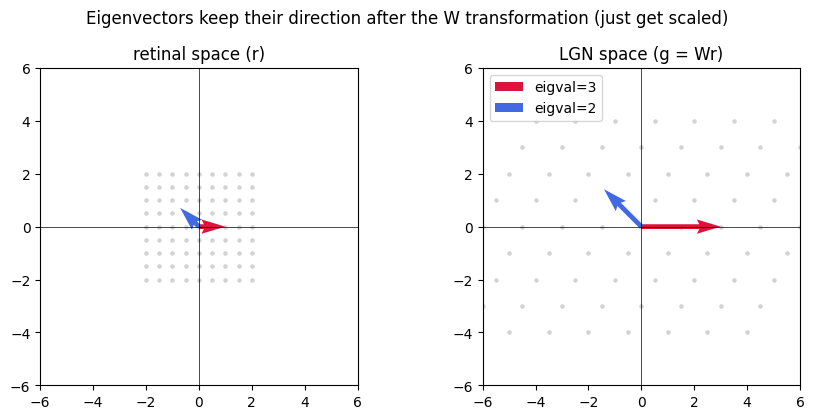

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
grid = np.array([[x, y] for x in np.linspace(-2, 2, 9) for y in np.linspace(-2, 2, 9)]).T

for ax, (title, pts) in zip(axes, [("retinal space (r)", grid), ("LGN space (g = Wr)", W @ grid)]):
    ax.scatter(*pts, s=5, color='lightgray')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_title(title); ax.set_aspect('equal'); ax.set_xlim(-6, 6); ax.set_ylim(-6, 6)

for i, color in enumerate(['crimson', 'royalblue']):
    v = eigvecs[:, i].real
    axes[0].quiver(0, 0, *v, angles='xy', scale_units='xy', scale=1, color=color, width=0.015)
    Wv = (W @ v)
    axes[1].quiver(0, 0, *Wv, angles='xy', scale_units='xy', scale=1, color=color, width=0.015,
                   label=f'eigval={eigvals[i]:.0f}')
axes[1].legend()
plt.suptitle('Eigenvectors keep their direction after the W transformation (just get scaled)')
plt.tight_layout()
plt.show()


### 3.3 Diagonalization: why the eigenbasis is worth the trouble

If we collect the eigenvectors as columns of a matrix $V$ and the
eigenvalues on the diagonal of $\Lambda$, then

$$W = V \Lambda V^{-1}$$

In the eigenbasis (i.e. after changing coordinates with $V$), the
transformation is *just* a diagonal scaling — no mixing between axes. This
is exactly what makes eigenstuff so useful: applying $W$ many times, or
solving equations involving $W$, becomes trivial once you're in this basis
(each axis scales independently, so $W^n = V \Lambda^n V^{-1}$ instead of
$n$ full matrix multiplications).


In [ ]:
V = eigvecs
Lambda = np.diag(eigvals)
W_reconstructed = (V @ Lambda @ np.linalg.inv(V)).real

print("Lambda (diagonal matrix of eigenvalues):\n", Lambda.real)
print("\nV @ Lambda @ V^-1 reconstructs W?", np.allclose(W, W_reconstructed))


Lambda (diagonal matrix of eigenvalues):
 [[3. 0.]
 [0. 2.]]

V @ Lambda @ V^-1 reconstructs W? True


**Takeaways**
- Solving `Wr = g` for `r` requires `W` to be invertible — the same rank/null-space condition from the matrices unit, now attached to a real question ("can downstream neurons recover the input?").
- Eigenvectors are the directions where a linear transformation acts as pure scaling; the eigenvalues tell you the scaling factor.
- Diagonalization ($W = V\Lambda V^{-1}$) is the formal version of "change to the eigenbasis" from lecture — it turns a general matrix multiplication into independent per-axis scaling.


---
## Exercise 4 — Rank and null space as neural coding *capacity*

Now let's use rank and null space for something with real stakes: deciding
whether a population of neurons can even in principle distinguish between
two different stimuli.

Suppose a small population of 2 neurons encodes a 3-dimensional stimulus
(e.g. the amount of red, green, and blue light in a patch). Each neuron's
response is some linear combination of the 3 stimulus components:

$$M = \begin{bmatrix} 1 & 0 & 1 \\ 0 & 1 & 1 \end{bmatrix}, \qquad
\text{response} = M \, \text{stimulus}$$


In [ ]:
M = np.array([[1., 0., 1.],
              [0., 1., 1.]])

rank_M = np.linalg.matrix_rank(M)
print(f"M is {M.shape[0]} x {M.shape[1]} (2 neurons encoding a 3D stimulus)")
print(f"rank(M) = {rank_M}")


M is 2 x 3 (2 neurons encoding a 3D stimulus)
rank(M) = 2


$M$ maps a 3D stimulus space down to a 2D response space, so by the
rank-nullity theorem there **must** be a nontrivial null space (dimension
$3 - \text{rank}(M) = 1$ here) — some direction in stimulus space that
produces exactly zero change in the neurons' output. Any two stimuli that
differ only along that direction are, as far as this population is
concerned, **identical**.


In [ ]:
null_M = null_space(M)
print("null space basis vector(s):\n", null_M)


null space basis vector(s):
 [[-0.577]
 [-0.577]
 [ 0.577]]


In [ ]:
stim_1 = np.array([1., 2., 0.])
response_1 = M @ stim_1

null_direction = null_M[:, 0]
stim_2 = stim_1 + 2.5 * null_direction        # a genuinely different stimulus...
response_2 = M @ stim_2

print("stimulus 1:", stim_1)
print("stimulus 2:", np.round(stim_2, 3))
print("response to stimulus 1:", response_1)
print("response to stimulus 2:", np.round(response_2, 3))
print("\nAre the two (different!) stimuli indistinguishable to this population?",
      np.allclose(response_1, response_2))


stimulus 1: [1. 2. 0.]
stimulus 2: [-0.443  0.557  1.443]
response to stimulus 1: [1. 2.]
response to stimulus 2: [1. 2.]

Are the two (different!) stimuli indistinguishable to this population? True


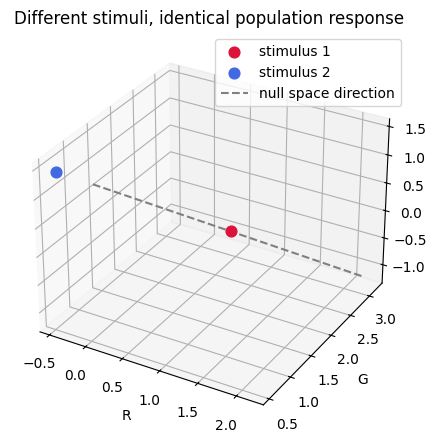

In [ ]:
fig = plt.figure(figsize=(5, 4.5))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*stim_1, color='crimson', s=60, label='stimulus 1')
ax.scatter(*stim_2, color='royalblue', s=60, label='stimulus 2')
ax.plot(*zip(stim_1 - 2*null_direction, stim_1 + 2*null_direction),
        color='gray', ls='--', label='null space direction')
ax.set_xlabel('R'); ax.set_ylabel('G'); ax.set_zlabel('B')
ax.legend()
ax.set_title('Different stimuli, identical population response')
plt.tight_layout()
plt.show()


This is the real-world meaning of "rank" for a neural population: **the
rank of the encoding matrix is the effective dimensionality of what the
population can actually represent**, regardless of how many stimulus
dimensions exist out in the world. A population of $N$ neurons can
distinguish at most $N$ independent stimulus dimensions — adding more
input dimensions than you have independent neurons just grows the null
space, not the population's discriminative power. This is exactly the
flip side of the invertibility question from Exercise 3: there, the retina
had as many outputs as inputs and no null space, so nothing was lost; here,
compressing 3 dimensions into 2 responses necessarily loses information.

**Takeaways**
- Null space isn't just an abstract linear-algebra object — for an encoding matrix, it's literally the set of stimulus differences a population *cannot* perceive.
- Rank of the encoding matrix = effective dimensionality of the neural code.
- This is one reason population recordings care so much about "how many neurons do we need" — it's a rank question.
